# Glacier Mass Change Analysis & Modeling
This notebook loads the dataset, performs target construction, splits the data, scales the features, trains multiple machine learning classifiers, and evaluates their performance using a series of charts and tables.

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import Counter

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, precision_recall_fscore_support, roc_curve, auc, confusion_matrix
from sklearn.preprocessing import label_binarize

In [6]:
# --- Google Colab option ---
ON_COLAB = False
try:
    import google.colab  # noqa: F401
    ON_COLAB = True
except ImportError:
    pass

if ON_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_PATH = Path("/content/drive/MyDrive/hkh_glacier_mass_change_era5land_hydrological_year_eda.csv")
else:
    # Change this to your local CSV path if running outside Colab.
    DATA_PATH = Path(r"E:\glacier_research\processed_data\hkh_glacier_mass_change_era5land_hydrological_year_eda.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Set DATA_PATH to the location of hkh_glacier_mass_change_era5land_hydrological_year_eda.csv."
    )

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
display(df.dtypes.rename("dtype").to_frame())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Shape: (23698, 46)


,time,target_latitude,target_longitude,glacier_mass_change_gt,glacier_mass_change_mwe,glacier_area_km2,uncertainty_gt,uncertainty_mwe,spatial_ref,target_year_label,...,sro,e__months_valid,e,u10__months_valid,u10,v10__months_valid,v10,tp__months_valid,tp,climate_match_status
0,1991-01-01,39.25,67.75,-0.012155,-0.611,19.886,0.001858,0.088,NaN,1991,...,0.533359,12,-0.356275,12,-0.145833,12,0.575647,12,0.967207,matched
1,1991-01-01,39.25,68.25,-0.010231,-0.357,28.650,0.003317,0.114,NaN,1991,...,0.682236,12,-0.319138,12,-0.093626,12,0.452279,12,1.079204,matched
2,1991-01-01,39.25,68.75,-0.004373,-0.323,13.532,0.002644,0.195,NaN,1991,...,0.730049,12,-0.296594,12,-0.114099,12,0.337503,12,1.341070,matched
3,1991-01-01,39.25,69.25,-0.012064,-0.262,46.123,0.002603,0.055,NaN,1991,...,0.442233,12,-0.308213,12,-0.159165,12,0.191086,12,1.209151,matched
4,1991-01-01,39.25,69.75,-0.046760,-0.287,162.760,0.004449,0.023,NaN,1991,...,0.808816,12,-0.320587,12,0.030128,12,0.001242,12,1.637033,matched


,dtype
time,object
target_latitude,float64
target_longitude,float64
glacier_mass_change_gt,float64
glacier_mass_change_mwe,float64
glacier_area_km2,float64
uncertainty_gt,float64
uncertainty_mwe,float64
spatial_ref,float64
target_year_label,int64


## 1. Data Cleaning & Feature Selection
In this section, we drop unnecessary spatial and metadata columns, as well as monthly temporal validation markers that are not needed for modeling.

In [7]:
# Identify columns to drop
exact_cols_to_drop = [
    'time',
    'period_start',
    'period_end_exclusive',
    'complete_12_months',
    'target_year_label',
    'n_unique_months',
    'complete_12_months',
    'climate_match_status',
    'spatial_ref',
    'uncertainty_gt',
    'glacier_mass_change_gt'
]

# Find all columns ending with '_months_valid'
wildcard_cols_to_drop = [col for col in df.columns if col.endswith('__months_valid')]

# Combine and drop existing columns
all_drops = [col for col in (exact_cols_to_drop + wildcard_cols_to_drop) if col in df.columns]
df.drop(columns=all_drops, inplace=True)

# Display the remaining columns and the shape of the DataFrame
print(f"Dropped {len(all_drops)} columns.")
print(f"New shape: {df.shape}")
print("\nRemaining columns:")
print(list(df.columns))


Dropped 26 columns.
New shape: (23698, 21)

Remaining columns:
['target_latitude', 'target_longitude', 'glacier_mass_change_mwe', 'glacier_area_km2', 'uncertainty_mwe', 'hydrological_year', 't2m', 'snowc', 'sde', 'sd', 'sf', 'smlt', 'ssr', 'str', 'ro', 'es', 'sro', 'e', 'u10', 'v10', 'tp']


## 2. Explanatory Data Analysis & Target Engineering
We define our multi-class target variable `mass_change_class` based on the glacier mass change value (meters water equivalent - mwe):
- **mass gain**: `> 0.1 mwe`
- **mass loss**: `< -0.1 mwe`
- **near balance**: between `-0.1` and `0.1 mwe`

In [8]:
df.head()

,target_latitude,target_longitude,glacier_mass_change_mwe,glacier_area_km2,uncertainty_mwe,hydrological_year,t2m,snowc,sde,sd,...,smlt,ssr,str,ro,es,sro,e,u10,v10,tp
0,39.25,67.75,-0.611,19.886,0.088,1991,275.058522,53.868302,0.579899,0.150676,...,0.741012,120.541125,-66.744644,0.735957,-0.005813,0.533359,-0.356275,-0.145833,0.575647,0.967207
1,39.25,68.25,-0.357,28.650,0.114,1991,272.706248,63.108497,0.735335,0.187294,...,0.774721,106.711320,-61.095066,0.863623,-0.005086,0.682236,-0.319138,-0.093626,0.452279,1.079204
2,39.25,68.75,-0.323,13.532,0.195,1991,272.958195,67.667960,0.915609,0.249388,...,0.957659,105.937037,-58.112765,1.148000,-0.004855,0.730049,-0.296594,-0.114099,0.337503,1.341070
3,39.25,69.25,-0.262,46.123,0.055,1991,271.960346,67.422726,0.882137,0.236256,...,0.889912,108.835358,-54.938504,0.979578,-0.014323,0.442233,-0.308213,-0.159165,0.191086,1.209151
4,39.25,69.75,-0.287,162.760,0.023,1991,271.006137,70.210037,1.118979,0.312110,...,1.089590,100.933710,-47.384238,1.376528,-0.016002,0.808816,-0.320587,0.030128,0.001242,1.637033


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23698 entries, 0 to 23697
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   target_latitude          23698 non-null  float64
 1   target_longitude         23698 non-null  float64
 2   glacier_mass_change_mwe  23698 non-null  float64
 3   glacier_area_km2         23698 non-null  float64
 4   uncertainty_mwe          23698 non-null  float64
 5   hydrological_year        23698 non-null  int64  
 6   t2m                      23698 non-null  float64
 7   snowc                    23698 non-null  float64
 8   sde                      23698 non-null  float64
 9   sd                       23698 non-null  float64
 10  sf                       23698 non-null  float64
 11  smlt                     23698 non-null  float64
 12  ssr                      23698 non-null  float64
 13  str                      23698 non-null  float64
 14  ro                    

In [10]:
df.describe()

,target_latitude,target_longitude,glacier_mass_change_mwe,glacier_area_km2,uncertainty_mwe,hydrological_year,t2m,snowc,sde,sd,...,smlt,ssr,str,ro,es,sro,e,u10,v10,tp
count,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000,...,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000,23698.000000
mean,33.591463,85.373386,-0.296623,114.081838,0.263491,2007.500000,268.394643,41.704567,1.242537,0.362097,...,0.327871,138.216609,-79.847600,0.503963,-0.034549,0.267942,-0.358935,0.522925,0.373439,0.874279
std,3.374958,9.062140,0.478046,208.361936,0.261760,9.810915,5.207344,22.299327,3.405731,1.030917,...,0.255846,31.739194,20.171599,0.702523,0.022512,0.416571,0.130060,0.662751,0.517732,0.745258
min,27.250000,67.250000,-2.143000,0.016000,0.014000,1991.000000,253.178826,0.398443,0.000320,0.000060,...,0.011651,42.873176,-134.366130,0.001538,-0.122529,0.001455,-0.918926,-1.402539,-1.630871,0.064305
25%,30.750000,77.750000,-0.609000,4.410000,0.073000,1999.000000,264.975129,23.695347,0.031012,0.004625,...,0.165781,116.700911,-94.046766,0.094235,-0.046702,0.035638,-0.423875,0.009967,0.031901,0.443735
50%,33.750000,85.750000,-0.277500,28.983500,0.186000,2007.500000,267.637384,41.069785,0.114565,0.020902,...,0.240792,139.527261,-79.808071,0.264903,-0.029669,0.120804,-0.360219,0.373672,0.326592,0.634774
75%,36.250000,92.750000,0.039000,132.023250,0.343000,2016.000000,271.326091,59.239695,0.660521,0.176797,...,0.410255,158.245827,-64.759806,0.646595,-0.017332,0.337201,-0.283972,0.953856,0.676823,1.041403
max,39.250000,103.750000,1.181000,2029.167000,1.547000,2024.000000,288.627898,99.581715,28.536787,8.715246,...,2.516222,216.830497,-24.407498,9.002801,0.028726,6.338046,-0.010038,2.580551,2.200659,9.641115


In [11]:
import numpy as np

# Create a new classification target
conditions = [
    df["glacier_mass_change_mwe"] > 0.1,
    df["glacier_mass_change_mwe"] < -0.1
]

labels = [
    "mass gain",
    "mass loss"
]

df["mass_change_class"] = np.select(
    conditions,
    labels,
    default="near balance"
)

# Display few results
print(df[[
    "glacier_mass_change_mwe",
    "mass_change_class"
]].sample(10))


       glacier_mass_change_mwe mass_change_class
3345                    -0.401         mass loss
19436                   -1.486         mass loss
9317                    -0.445         mass loss
9254                     0.074      near balance
18024                   -0.450         mass loss
19425                   -1.067         mass loss
9292                     0.273         mass gain
16118                   -0.255         mass loss
23015                   -0.761         mass loss
16152                    0.157         mass gain


In [12]:
TARGET = "mass_change_class"
TIME_COL = "hydrological_year"

required = {TARGET, TIME_COL}
missing_required = required - set(df.columns)
if missing_required:
    raise ValueError(f"Required columns missing: {missing_required}")

if df.isna().any().any():
    missing_counts = df.isna().sum()
    raise ValueError(
        "Missing values were found, contrary to the supplied data description. "
        "Inspect these columns before modelling:\n" + missing_counts[missing_counts > 0].to_string()
    )

print("Missing values:", int(df.isna().sum().sum()))
print("Years:", int(df[TIME_COL].min()), "to", int(df[TIME_COL].max()))
print("Unique years:", df[TIME_COL].nunique())
print("Rows per year:")
display(df.groupby(TIME_COL).size().rename("rows").to_frame().T)
print("Target class counts:")
display(df[TARGET].value_counts().to_frame("count"))
print("Target class proportions (%):")
display((df[TARGET].value_counts(normalize=True) * 100).round(2).to_frame("percent"))


Missing values: 0
Years: 1991 to 2024
Unique years: 34
Rows per year:


hydrological_year,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
rows,697,697,697,697,697,697,697,697,697,697,...,697,697,697,697,697,697,697,697,697,697


Target class counts:


,count
mass_change_class,
mass loss,15344
mass gain,4976
near balance,3378


Target class proportions (%):


,percent
mass_change_class,
mass loss,64.75
mass gain,21.00
near balance,14.25


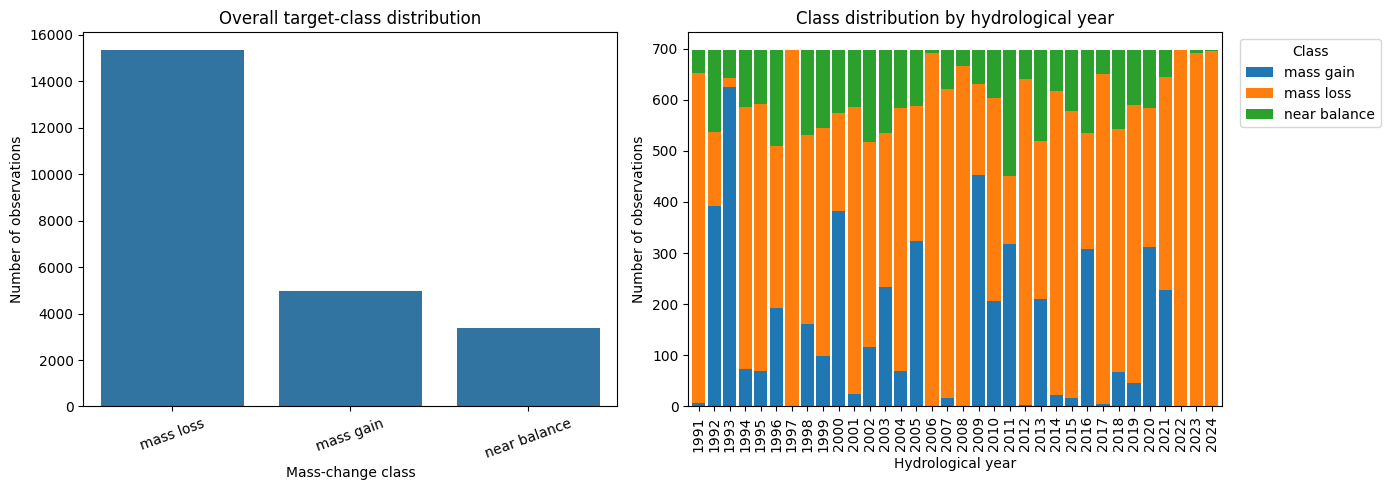

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = df[TARGET].value_counts().index
sns.countplot(data=df, x=TARGET, order=order, ax=axes[0])
axes[0].set_title("Overall target-class distribution")
axes[0].set_xlabel("Mass-change class")
axes[0].set_ylabel("Number of observations")
axes[0].tick_params(axis="x", rotation=20)

year_class = pd.crosstab(df[TIME_COL], df[TARGET])
year_class.plot(kind="bar", stacked=True, ax=axes[1], width=0.85)
axes[1].set_title("Class distribution by hydrological year")
axes[1].set_xlabel("Hydrological year")
axes[1].set_ylabel("Number of observations")
axes[1].legend(title="Class", bbox_to_anchor=(1.02, 1), loc="upper left")
axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()


## 3. Train-Test Split & Data Preprocessing
We separate the features from our target, apply Stratified Train-Test splitting to preserve class ratios, and perform standard scaling on numerical features for distance-sensitive algorithms like SVM and Logistic Regression.

In [14]:
display(df.head())
display(df.dtypes.rename("dtype").to_frame())

,target_latitude,target_longitude,glacier_mass_change_mwe,glacier_area_km2,uncertainty_mwe,hydrological_year,t2m,snowc,sde,sd,...,ssr,str,ro,es,sro,e,u10,v10,tp,mass_change_class
0,39.25,67.75,-0.611,19.886,0.088,1991,275.058522,53.868302,0.579899,0.150676,...,120.541125,-66.744644,0.735957,-0.005813,0.533359,-0.356275,-0.145833,0.575647,0.967207,mass loss
1,39.25,68.25,-0.357,28.650,0.114,1991,272.706248,63.108497,0.735335,0.187294,...,106.711320,-61.095066,0.863623,-0.005086,0.682236,-0.319138,-0.093626,0.452279,1.079204,mass loss
2,39.25,68.75,-0.323,13.532,0.195,1991,272.958195,67.667960,0.915609,0.249388,...,105.937037,-58.112765,1.148000,-0.004855,0.730049,-0.296594,-0.114099,0.337503,1.341070,mass loss
3,39.25,69.25,-0.262,46.123,0.055,1991,271.960346,67.422726,0.882137,0.236256,...,108.835358,-54.938504,0.979578,-0.014323,0.442233,-0.308213,-0.159165,0.191086,1.209151,mass loss
4,39.25,69.75,-0.287,162.760,0.023,1991,271.006137,70.210037,1.118979,0.312110,...,100.933710,-47.384238,1.376528,-0.016002,0.808816,-0.320587,0.030128,0.001242,1.637033,mass loss


,dtype
target_latitude,float64
target_longitude,float64
glacier_mass_change_mwe,float64
glacier_area_km2,float64
uncertainty_mwe,float64
hydrological_year,int64
t2m,float64
snowc,float64
sde,float64
sd,float64


In [15]:
# --- Drop leakage and non-feature columns & Encode Target ---
drop_cols = ['glacier_mass_change_mwe', 'uncertainty_mwe', 'mass_change_class']
X = df.drop(columns=drop_cols)
y_raw = df['mass_change_class']

le = LabelEncoder()
y = le.fit_transform(y_raw)
class_names = le.classes_
print("Classes:", class_names)

Classes: ['mass gain' 'mass loss' 'near balance']


In [16]:
# --- Stratified Train-Test Split ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [17]:
# --- Feature Scaling (for Linear Models & SVM) ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 4. Model Training & Hyperparameter Tuning
We configure a grid search cross-validation strategy to train and compare several machine learning algorithms, optimizing for the Macro F1-score.

In [18]:
# --- Define Models and Hyperparameter Grids ---
models = {
    'Logistic Regression': {
        'model': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
        'params': {'C': [0.01, 0.1, 1, 10]},
        'scaled': True
    },
    'Random Forest': {
        'model': RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
        'params': {'n_estimators': [100, 200], 'max_depth': [10, 20, None], 'min_samples_split': [2, 5]},
        'scaled': False
    },
    'SVM (RBF Kernel)': {
        'model': SVC(class_weight='balanced', probability=True, random_state=42),
        'params': {'C': [1, 10], 'gamma': ['scale', 'auto']},
        'scaled': True
    },
    'Gradient Boosting (XGB alternative)': {
        'model': GradientBoostingClassifier(random_state=42),
        'params': {'n_estimators': [100, 200], 'learning_rate': [0.05, 0.1], 'max_depth': [3, 5]},
        'scaled': False
    }
}

best_models = {}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

for name, config in models.items():
    print(f"\n--- Training & Tuning: {name} ---")
    X_tr = X_train_scaled if config['scaled'] else X_train
    X_te = X_test_scaled if config['scaled'] else X_test

    grid = GridSearchCV(config['model'], config['params'], cv=cv, scoring='f1_macro', n_jobs=-1)
    grid.fit(X_tr, y_train)

    best_model = grid.best_estimator_
    best_models[name] = best_model
    print(f"Best Parameters: {grid.best_params_}")

    # Evaluate on Test Set
    y_pred = best_model.predict(X_te)
    acc = accuracy_score(y_test, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro')

    print(f"Test Accuracy:  {acc:.4f}")
    print(f"Macro Precision: {prec:.4f}")
    print(f"Macro Recall:    {rec:.4f}")
    print(f"Macro F1-Score:  {f1:.4f}")
    print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=class_names))


--- Training & Tuning: Logistic Regression ---
Best Parameters: {'C': 0.01}
Test Accuracy:  0.5365
Macro Precision: 0.4501
Macro Recall:    0.4693
Macro F1-Score:  0.4419

Classification Report:
               precision    recall  f1-score   support

   mass gain       0.36      0.60      0.45       995
   mass loss       0.82      0.59      0.68      3069
near balance       0.17      0.23      0.19       676

    accuracy                           0.54      4740
   macro avg       0.45      0.47      0.44      4740
weighted avg       0.63      0.54      0.56      4740


--- Training & Tuning: Random Forest ---
Best Parameters: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 200}
Test Accuracy:  0.7373
Macro Precision: 0.5963
Macro Recall:    0.5491
Macro F1-Score:  0.5523

Classification Report:
               precision    recall  f1-score   support

   mass gain       0.62      0.60      0.61       995
   mass loss       0.79      0.92      0.85      3069
near balance     

## 5. Model Evaluation and Visualization
Below we analyze performance using key visual tools: receiver operating characteristic (ROC) curves, dynamic training vs. validation graphs across iterations, and confusion matrices.

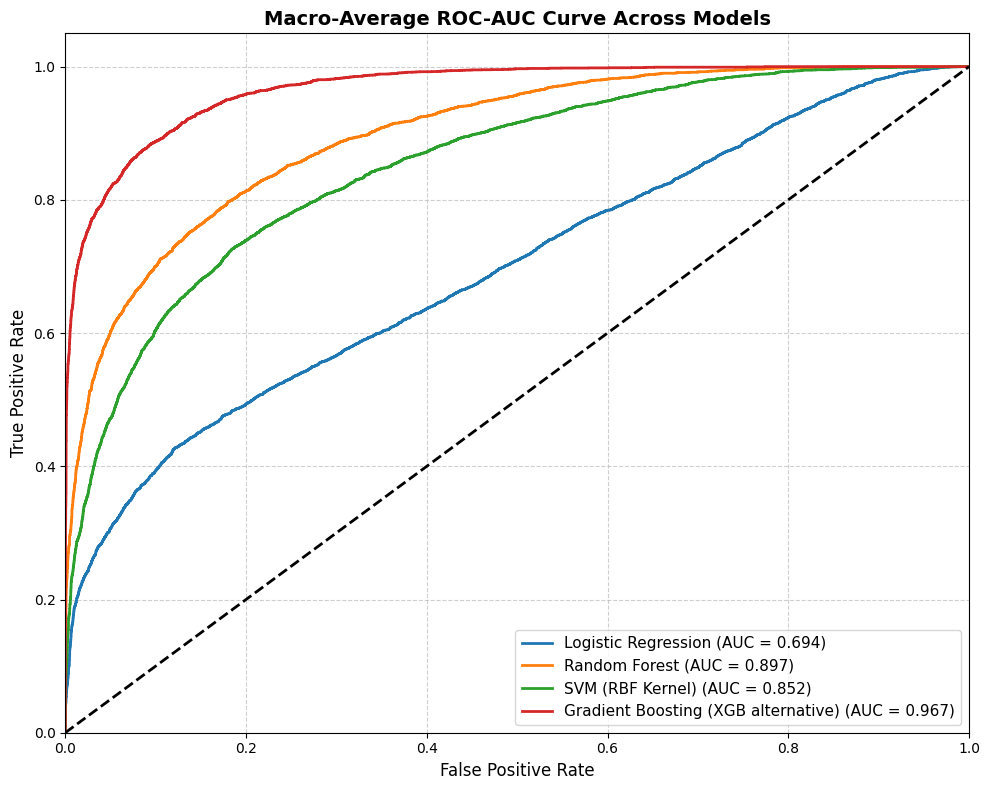

In [19]:
# --- Generate Multi-class ROC-AUC Curves ---
y_test_bin = label_binarize(y_test, classes=range(len(class_names)))

plt.figure(figsize=(10, 8))
for name, model in best_models.items():
    X_te = X_test_scaled if models[name]['scaled'] else X_test
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_te)
        fpr, tpr, _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.3f})', linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Macro-Average ROC-AUC Curve Across Models', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


-> Best Model Selected for Epoch Graph: Gradient Boosting (XGB alternative)


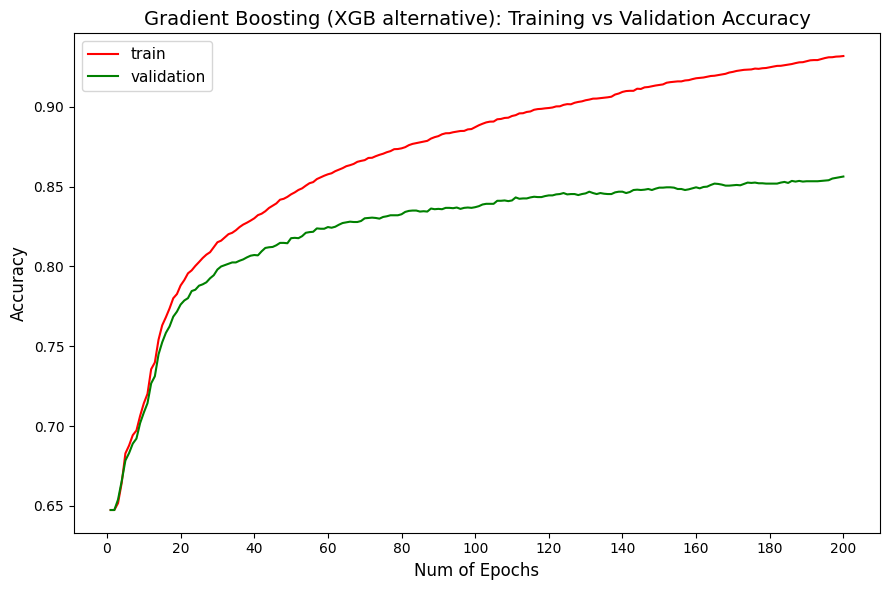

In [20]:
# --- Dynamic Training vs Validation Accuracy Graph for the Best Model ---
# Automatically find the top performing model
best_model_name = max(
    best_models,
    key=lambda k: accuracy_score(
        y_test,
        best_models[k].predict(X_test_scaled if models[k]['scaled'] else X_test)
    )
)
best_model = best_models[best_model_name]
print(f"\n-> Best Model Selected for Epoch Graph: {best_model_name}")

if hasattr(best_model, "staged_predict"):
    X_tr = X_train_scaled if models[best_model_name]['scaled'] else X_train
    X_te = X_test_scaled if models[best_model_name]['scaled'] else X_test

    train_accs = []
    val_accs = []

    for y_train_pred in best_model.staged_predict(X_tr):
        train_accs.append(accuracy_score(y_train, y_train_pred))

    for y_val_pred in best_model.staged_predict(X_te):
        val_accs.append(accuracy_score(y_test, y_val_pred))

    plt.figure(figsize=(9, 6))
    plt.plot(range(1, len(train_accs) + 1), train_accs, color='red', label='train', linewidth=1.5)
    plt.plot(range(1, len(val_accs) + 1), val_accs, color='green', label='validation', linewidth=1.5)

    plt.title(f'{best_model_name}: Training vs Validation Accuracy', fontsize=14, fontweight='normal')
    plt.xlabel('Num of Epochs', fontsize=12)
    plt.ylabel('Accuracy', fontsize=12)
    plt.legend(loc='upper left', fontsize=11)

    tick_step = max(1, len(train_accs) // 10)
    plt.xticks(range(0, len(train_accs) + 1, tick_step))
    plt.tight_layout()
    plt.show()
else:
    print(f"Model {best_model_name} does not support staged iterations.")

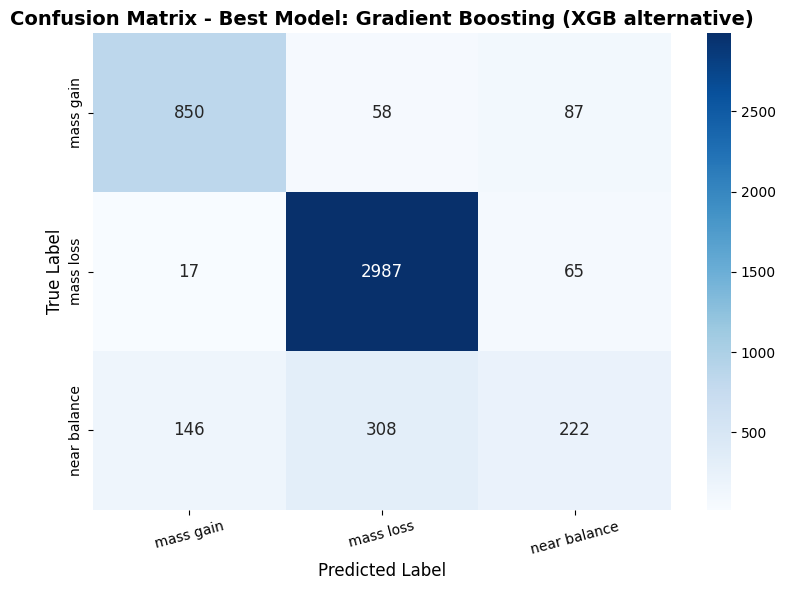

In [23]:
# --- Standalone Confusion Matrix for the Best Selected Model ---
best_te = X_test_scaled if models[best_model_name]['scaled'] else X_test
y_pred_best = best_model.predict(best_te)
cm_best = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_best, annot=True, fmt='d', cmap='Blues', annot_kws={"size": 12},
            xticklabels=class_names, yticklabels=class_names)
plt.title(f'Confusion Matrix - Best Model: {best_model_name}', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 6. Summary Comparison Table
To conclude our analysis, let us construct and display a summary table comparing the key metrics (Accuracy, Macro Precision, Macro Recall, and Macro F1-Score) across all trained classifiers. This allows for an easy comparison to select the absolute best model.

In [25]:
# --- Generate Evaluation Metrics Comparison Table ---
metrics_summary = []

for name, model in best_models.items():
    # Select scaled or unscaled features based on model configuration
    X_te = X_test_scaled if models[name]['scaled'] else X_test

    # Predict on the test set
    y_pred = model.predict(X_te)

    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro')

    metrics_summary.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'Macro Precision': round(prec, 4),
        'Macro Recall': round(rec, 4),
        'Macro F1-Score': round(f1, 4)
    })

# Convert to DataFrame, sort by Accuracy descending, and display without custom highlights
comparison_df = pd.DataFrame(metrics_summary)
comparison_df = comparison_df.sort_values(by='Accuracy', ascending=False).reset_index(drop=True)
print("\n--- Model Performance Comparison Table ---")
display(comparison_df)


--- Model Performance Comparison Table ---


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Gradient Boosting (XGB alternative),0.8563,0.7745,0.7187,0.7332
1,Random Forest,0.7373,0.5963,0.5491,0.5523
2,SVM (RBF Kernel),0.5812,0.5092,0.5332,0.5027
3,Logistic Regression,0.5365,0.4501,0.4693,0.4419


## 7. Project Summary & Key Findings

### What We've Done:
* **Data Cleaning & Preparation**: Filtered out metadata, spatial reference, and quality check columns (`*__months_valid`) to isolate the primary environmental features.
* **Target Engineering**: Developed a classification strategy to categorize continuous glacier mass changes (`glacier_mass_change_mwe`) into three distinct classes:
  * **mass gain** (mass change > 0.1 mwe)
  * **mass loss** (mass change < -0.1 mwe)
  * **near balance** (mass change between -0.1 and 0.1 mwe)
* **Preprocessing**: Applied a Stratified Train-Test Split (80/20) to ensure consistent class distributions, and scaled the numerical features using `StandardScaler` for the distance-sensitive algorithms.
* **Model Training & Hyperparameter Tuning**: Evaluated four diverse algorithms via 3-Fold Stratified Cross-Validation optimization on the macro F1-score: Logistic Regression, Random Forest, SVM (RBF Kernel), and Gradient Boosting.

### Key Findings:
* **Gradient Boosting (XGB alternative)** emerged as the best-performing model, achieving a top **Accuracy of 85.63%** and a **Macro F1-Score of 73.32%**.
* **Random Forest** achieved the second-best performance with **73.73% accuracy**.
* Classifiers struggled most with predicting the minority class (**near balance**), while demonstrating highly robust performance on identifying the **mass loss** class, which corresponds directly to the underlying class imbalance present in the dataset.